Load Library and Dataset

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import missingno as msno
sns.set(style='darkgrid')
import matplotlib.pyplot as plt

In [2]:
# Loading the dataset
data1 = pd.read_csv('Monday-WorkingHours.pcap_ISCX.csv')
data2 = pd.read_csv('Tuesday-WorkingHours.pcap_ISCX.csv')
data3 = pd.read_csv('Wednesday-workingHours.pcap_ISCX.csv')
data4 = pd.read_csv('Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv')
data5 = pd.read_csv('Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv')
data6 = pd.read_csv('Friday-WorkingHours-Morning.pcap_ISCX.csv')
data7 = pd.read_csv('Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv')
data8 = pd.read_csv('Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv')

In [3]:
data_list = [data1, data2, data3, data4, data5, data6, data7, data8]

print('Data dimensions: ')
for i, data in enumerate(data_list, start = 1):
  rows, cols = data.shape
  print(f'Data{i} -> {rows} rows, {cols} columns')

Data dimensions: 
Data1 -> 529918 rows, 79 columns
Data2 -> 445909 rows, 79 columns
Data3 -> 692703 rows, 79 columns
Data4 -> 170366 rows, 79 columns
Data5 -> 288602 rows, 79 columns
Data6 -> 191033 rows, 79 columns
Data7 -> 286467 rows, 79 columns
Data8 -> 225745 rows, 79 columns


In [4]:
data = pd.concat(data_list)
rows, cols = data.shape

print('New dimension:')
print(f'Number of rows: {rows}')
print(f'Number of columns: {cols}')
print(f'Total cells: {rows * cols}')

New dimension:
Number of rows: 2830743
Number of columns: 79
Total cells: 223628697


In [5]:
# Deleting dataframes after concating to save memory
for d in data_list: del d

In [6]:
# Renaming the columns by removing leading/trailing whitespace
col_names = {col: col.strip() for col in data.columns}
data.rename(columns = col_names, inplace = True)

In [7]:
pd.options.display.max_columns = 80
data.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,49188,4,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,3000000.0,5.000000e+05,4.0,0.0,4,4,4,4.0,0.0,4,4,0,0.0,0.0,0,0,0,0,0,0,40,0,5.000000e+05,0.0,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,49188,1,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,12000000.0,2.000000e+06,1.0,0.0,1,1,1,1.0,0.0,1,1,0,0.0,0.0,0,0,0,0,0,0,40,0,2.000000e+06,0.0,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,49188,1,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,12000000.0,2.000000e+06,1.0,0.0,1,1,1,1.0,0.0,1,1,0,0.0,0.0,0,0,0,0,0,0,40,0,2.000000e+06,0.0,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,49188,1,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,12000000.0,2.000000e+06,1.0,0.0,1,1,1,1.0,0.0,1,1,0,0.0,0.0,0,0,0,0,0,0,40,0,2.000000e+06,0.0,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,49486,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4000000.0,6.666667e+05,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,6.666667e+05,0.0,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,245,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


Data Clean

In [8]:
dups = data[data.duplicated()]
print(f'Number of duplicates: {len(dups)}')

Number of duplicates: 308381


In [9]:
data.drop_duplicates(inplace = True)
data.shape

(2522362, 79)

In [10]:
missing_val = data.isna().sum()
print(missing_val.loc[missing_val > 0])

Flow Bytes/s    353
dtype: int64


In [11]:
# Checking for infinity values
numeric_cols = data.select_dtypes(include = np.number).columns
inf_count = np.isinf(data[numeric_cols]).sum()
print(inf_count[inf_count > 0])

Flow Bytes/s      1211
Flow Packets/s    1564
dtype: int64


In [12]:
# Replacing any infinite values (positive or negative) with NaN (not a number)
print(f'Initial missing values: {data.isna().sum().sum()}')

data.replace([np.inf, -np.inf], np.nan, inplace = True)

print(f'Missing values after processing infinite values: {data.isna().sum().sum()}')

Initial missing values: 353
Missing values after processing infinite values: 3128


In [13]:
missing = data.isna().sum()
print(missing.loc[missing > 0])

Flow Bytes/s      1564
Flow Packets/s    1564
dtype: int64


In [14]:
data = data.reset_index(drop=True)

Visualisation

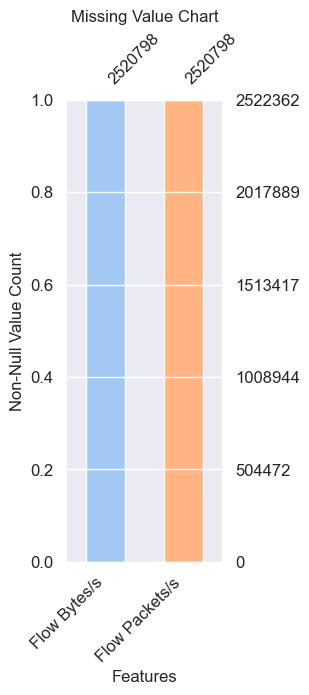

In [15]:
sns.set_palette('pastel')
colors = sns.color_palette()

missing_vals = [col for col in data.columns if data[col].isna().any()]

fig, ax = plt.subplots(figsize = (2, 6))
msno.bar(data[missing_vals], ax = ax, fontsize = 12, color = colors)
ax.set_xlabel('Features', fontsize = 12)
ax.set_ylabel('Non-Null Value Count', fontsize = 12)
ax.set_title('Missing Value Chart', fontsize = 12)
plt.show()

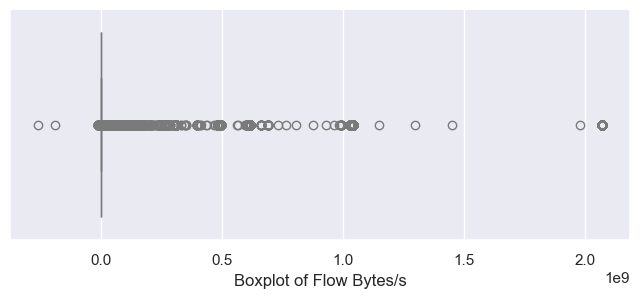

In [16]:
plt.figure(figsize = (8, 3))
sns.boxplot(x = data['Flow Bytes/s'])
plt.xlabel('Boxplot of Flow Bytes/s')
plt.show()

In [17]:
# Types of attacks & normal instances (BENIGN)
data['Label'].value_counts()

Label
BENIGN                        2096484
DoS Hulk                       172849
DDoS                           128016
PortScan                        90819
DoS GoldenEye                   10286
FTP-Patator                      5933
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1953
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

In [18]:
# Creating a dictionary that maps each label to its attack type
attack_map = {
    'BENIGN': 'BENIGN',
    'DDoS': 'DDoS',
    'DoS Hulk': 'DoS',
    'DoS GoldenEye': 'DoS',
    'DoS slowloris': 'DoS',
    'DoS Slowhttptest': 'DoS',
    'PortScan': 'Port Scan',
    'FTP-Patator': 'Brute Force',
    'SSH-Patator': 'Brute Force',
    'Bot': 'Bot',
    'Web Attack � Brute Force': 'Web Attack',
    'Web Attack � XSS': 'Web Attack',
    'Web Attack � Sql Injection': 'Web Attack',
    'Infiltration': 'Infiltration',
    'Heartbleed': 'Heartbleed'
}

# Creating a new column 'Attack Type' in the DataFrame based on the attack_map dictionary
data['Attack Type'] = data['Label'].map(attack_map)

In [19]:
data['Attack Type'].value_counts()

Attack Type
BENIGN          2096484
DoS              193748
DDoS             128016
Port Scan         90819
Brute Force        9152
Web Attack         2143
Bot                1953
Infiltration         36
Heartbleed           11
Name: count, dtype: int64

In [20]:
data.drop('Label', axis = 1, inplace = True)

In [21]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
data['Attack Number'] = le.fit_transform(data['Attack Type'])

print(data['Attack Number'].unique())

[0 2 4 5 8 6 1 7 3]


In [22]:
# Printing corresponding attack type for each encoded value
encoded_values = data['Attack Number'].unique()
for val in sorted(encoded_values):
    print(f"{val}: {le.inverse_transform([val])[0]}")

0: BENIGN
1: Bot
2: Brute Force
3: DDoS
4: DoS
5: Heartbleed
6: Infiltration
7: Port Scan
8: Web Attack


In [23]:
# Printing corresponding attack type for each encoded value
encoded_values = data['Attack Number'].unique()
for val in sorted(encoded_values):
    print(f"{val}: {le.inverse_transform([val])[0]}")

0: BENIGN
1: Bot
2: Brute Force
3: DDoS
4: DoS
5: Heartbleed
6: Infiltration
7: Port Scan
8: Web Attack


In [24]:
corr = data.corr(numeric_only = True).round(2)
corr.style.background_gradient(cmap = 'coolwarm', axis = None).format(precision = 2)

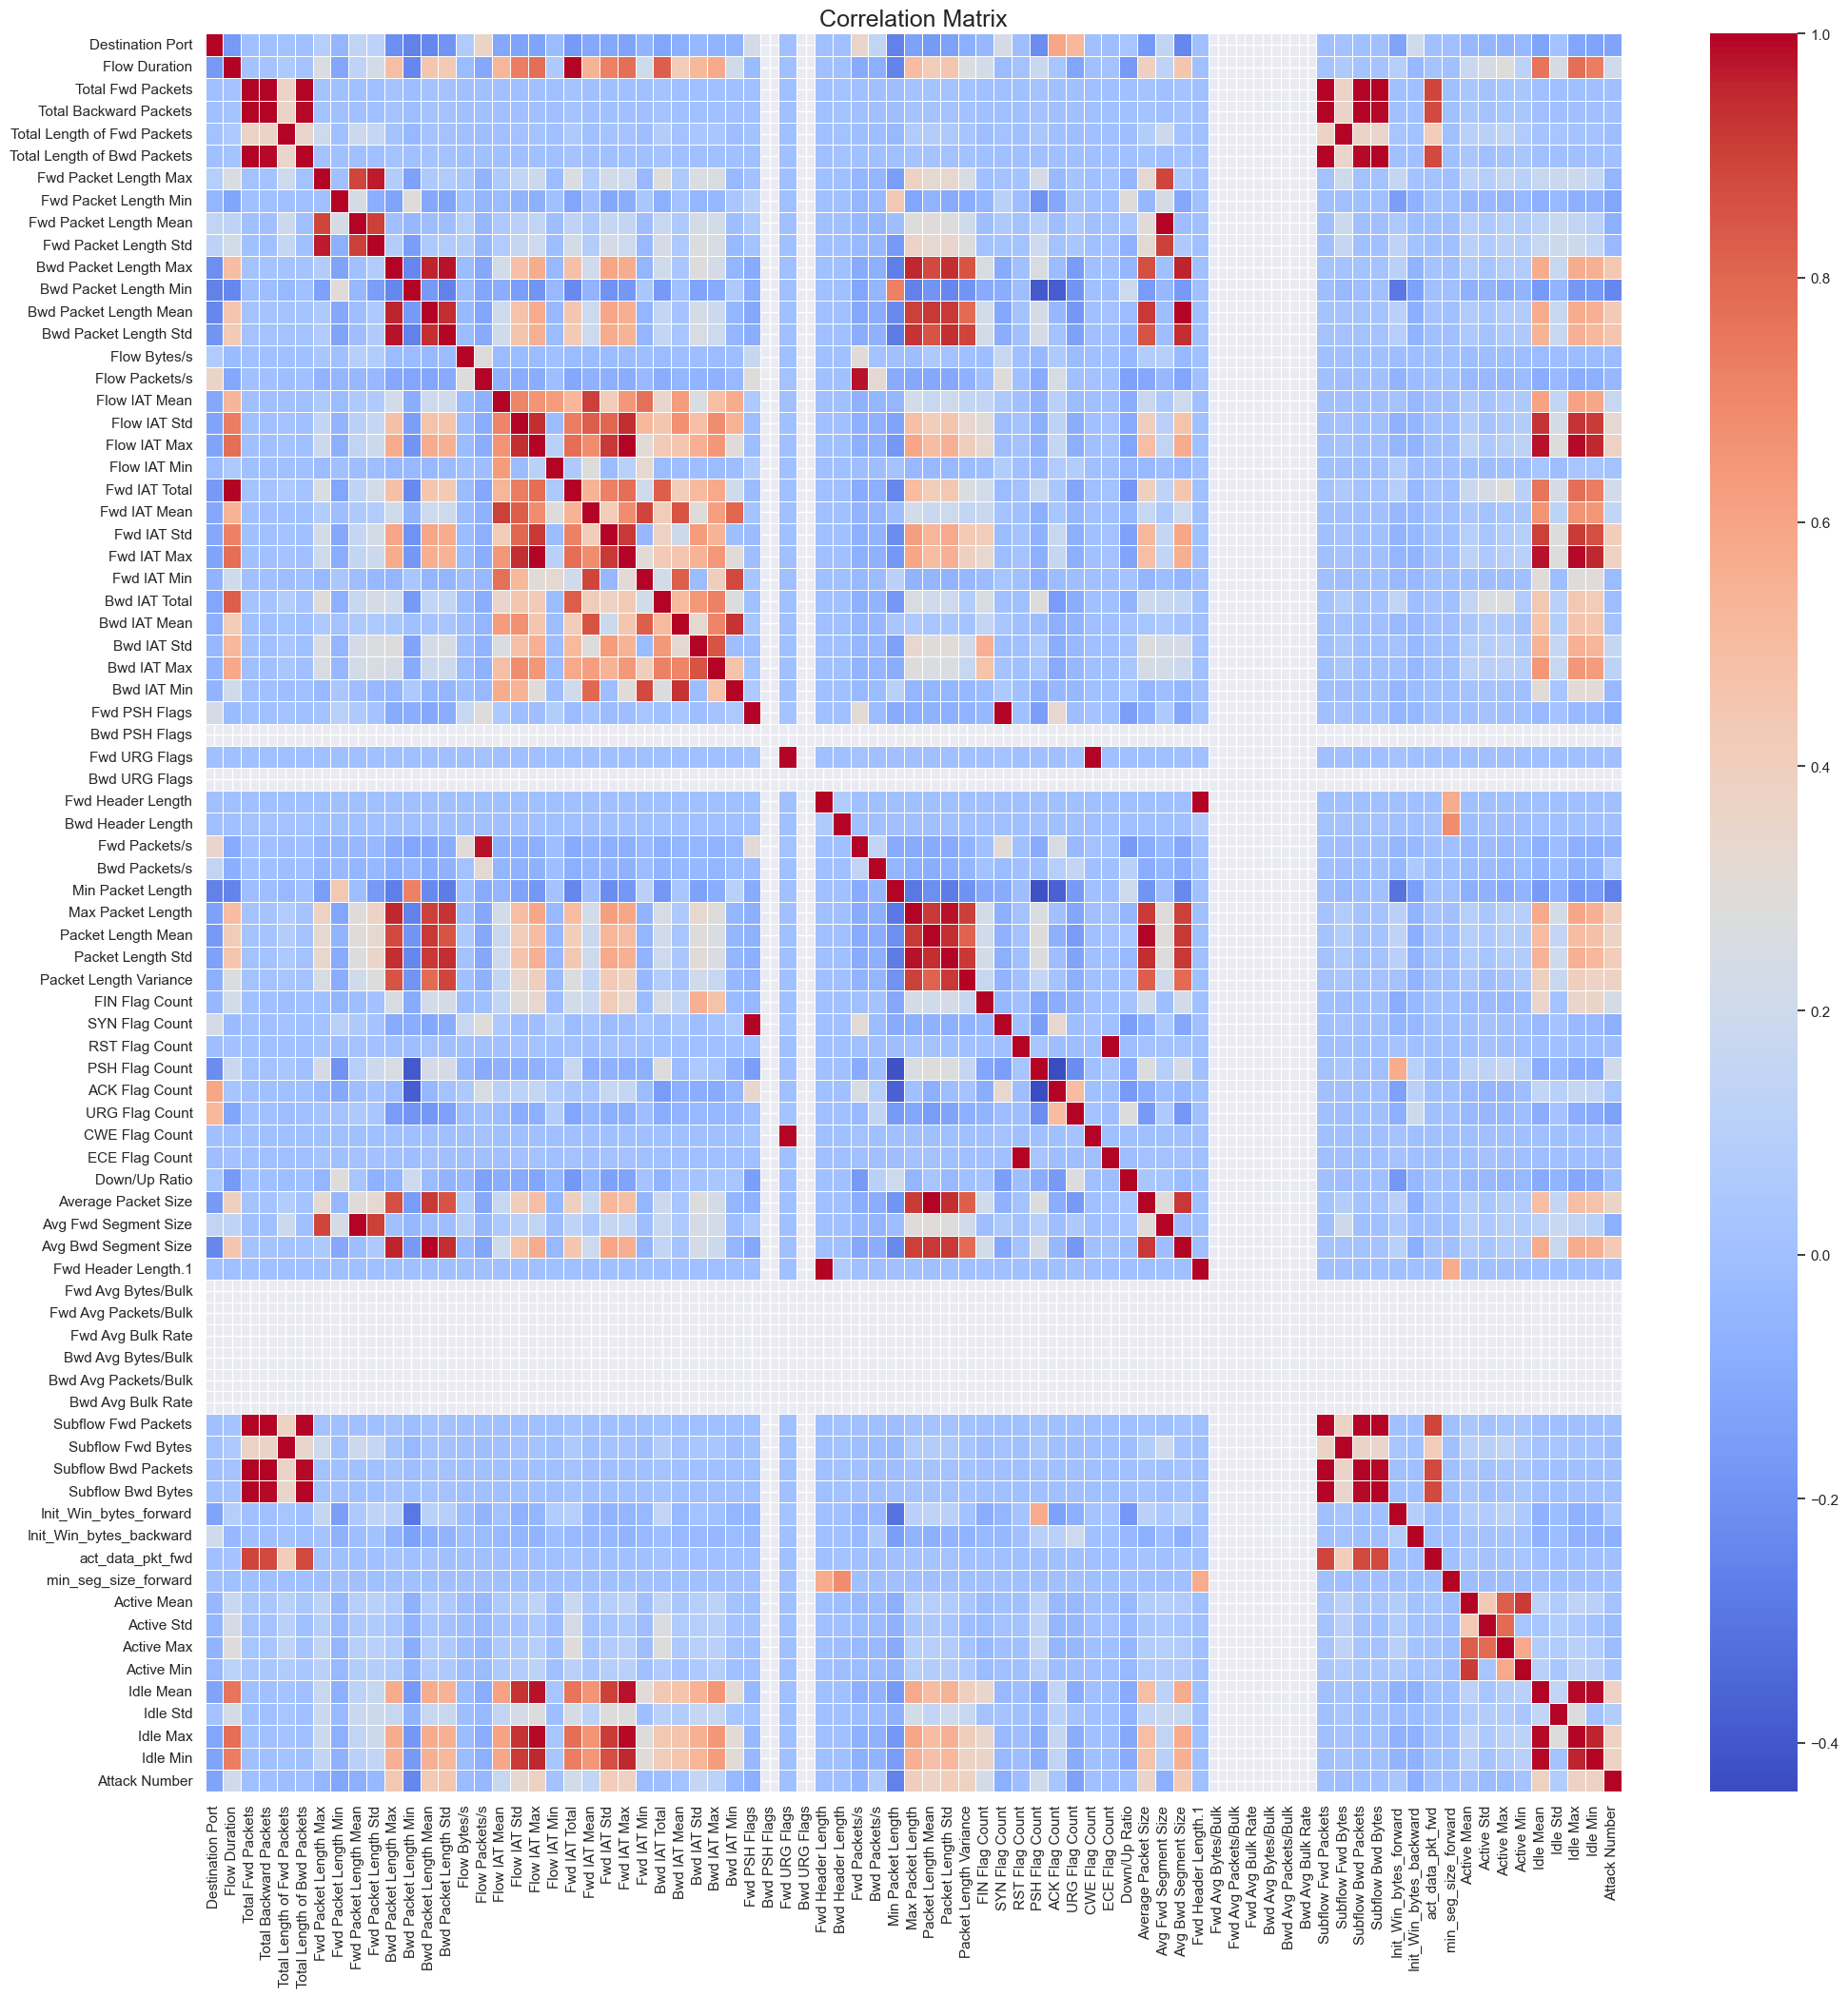

In [25]:
fig, ax = plt.subplots(figsize = (24, 24))
sns.heatmap(corr, cmap = 'coolwarm', annot = False, linewidth = 0.5)
plt.title('Correlation Matrix', fontsize = 18)
plt.show()

In [26]:
# Positive correlation features for 'Attack Number'
pos_corr_features = corr['Attack Number'][(corr['Attack Number'] > 0) & (corr['Attack Number'] < 1)].index.tolist()

print("Features with positive correlation with 'Attack Number':\n")
for i, feature in enumerate(pos_corr_features, start = 1):
    corr_value = corr.loc[feature, 'Attack Number']
    print('{:<3} {:<24} :{}'.format(f'{i}.', feature, corr_value))

Features with positive correlation with 'Attack Number':

1.  Flow Duration            :0.21
2.  Bwd Packet Length Max    :0.44
3.  Bwd Packet Length Mean   :0.43
4.  Bwd Packet Length Std    :0.45
5.  Flow IAT Mean            :0.17
6.  Flow IAT Std             :0.33
7.  Flow IAT Max             :0.38
8.  Flow IAT Min             :0.01
9.  Fwd IAT Total            :0.22
10. Fwd IAT Mean             :0.15
11. Fwd IAT Std              :0.41
12. Fwd IAT Max              :0.38
13. Bwd IAT Mean             :0.01
14. Bwd IAT Std              :0.16
15. Bwd IAT Max              :0.12
16. Bwd Packets/s            :0.07
17. Max Packet Length        :0.4
18. Packet Length Mean       :0.37
19. Packet Length Std        :0.41
20. Packet Length Variance   :0.38
21. FIN Flag Count           :0.23
22. PSH Flag Count           :0.21
23. ACK Flag Count           :0.03
24. Average Packet Size      :0.36
25. Avg Bwd Segment Size     :0.43
26. Init_Win_bytes_forward   :0.04
27. Active Mean              :0.0

In [27]:
# Checking for columns with zero standard deviation (the blank squares in the heatmap)
std = data.std(numeric_only = True)
zero_std_cols = std[std == 0].index.tolist()
zero_std_cols

['Bwd PSH Flags',
 'Bwd URG Flags',
 'Fwd Avg Bytes/Bulk',
 'Fwd Avg Packets/Bulk',
 'Fwd Avg Bulk Rate',
 'Bwd Avg Bytes/Bulk',
 'Bwd Avg Packets/Bulk',
 'Bwd Avg Bulk Rate']

Visualization of linear representation of columns (NUmerical values)

In [28]:
# Data sampling for data analysis
sample_size = int(0.2 * len(data)) # 20% of the original size
sampled_data = data.sample(n = sample_size, replace = False, random_state = 0)
sampled_data.shape

(504472, 80)

In [29]:
# To assess if a sample is representative of the population and comparison of descriptive statistics (mean)
numeric_cols = data.select_dtypes(include = [np.number]).columns.tolist()
print('Descriptive Statistics Comparison (mean):\n')
print('{:<32s}{:<22s}{:<22s}{}'.format('Feature', 'Original Dataset', 'Sampled Dataset', 'Variation Percentage'))
print('-' * 96)

high_variations = []
for col in numeric_cols:
    old = data[col].describe()[1]
    new = sampled_data[col].describe()[1]
    if old == 0:
        pct = 0
    else:
        pct = abs((new - old) / old)
    if pct * 100 > 5:
        high_variations.append((col, pct * 100))
    print('{:<32s}{:<22.6f}{:<22.6f}{:<2.2%}'.format(col, old, new, pct))

Descriptive Statistics Comparison (mean):

Feature                         Original Dataset      Sampled Dataset       Variation Percentage
------------------------------------------------------------------------------------------------


C:\Users\User\AppData\Local\Temp\ipykernel_16668\580325769.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  old = data[col].describe()[1]
C:\Users\User\AppData\Local\Temp\ipykernel_16668\580325769.py:10: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  new = sampled_data[col].describe()[1]


Destination Port                8704.762165           8686.623973           0.21%


C:\Users\User\AppData\Local\Temp\ipykernel_16668\580325769.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  old = data[col].describe()[1]
C:\Users\User\AppData\Local\Temp\ipykernel_16668\580325769.py:10: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  new = sampled_data[col].describe()[1]


Flow Duration                   16581323.773163       16502842.174093       0.47%


...

Idle Max                        9757716.419817        9707974.839432        0.51%


C:\Users\User\AppData\Local\Temp\ipykernel_16668\580325769.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  old = data[col].describe()[1]
C:\Users\User\AppData\Local\Temp\ipykernel_16668\580325769.py:10: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  new = sampled_data[col].describe()[1]


Idle Min                        8887156.719966        8839664.611709        0.53%


C:\Users\User\AppData\Local\Temp\ipykernel_16668\580325769.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  old = data[col].describe()[1]
C:\Users\User\AppData\Local\Temp\ipykernel_16668\580325769.py:10: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  new = sampled_data[col].describe()[1]


Attack Number                   0.726480              0.731022              0.63%


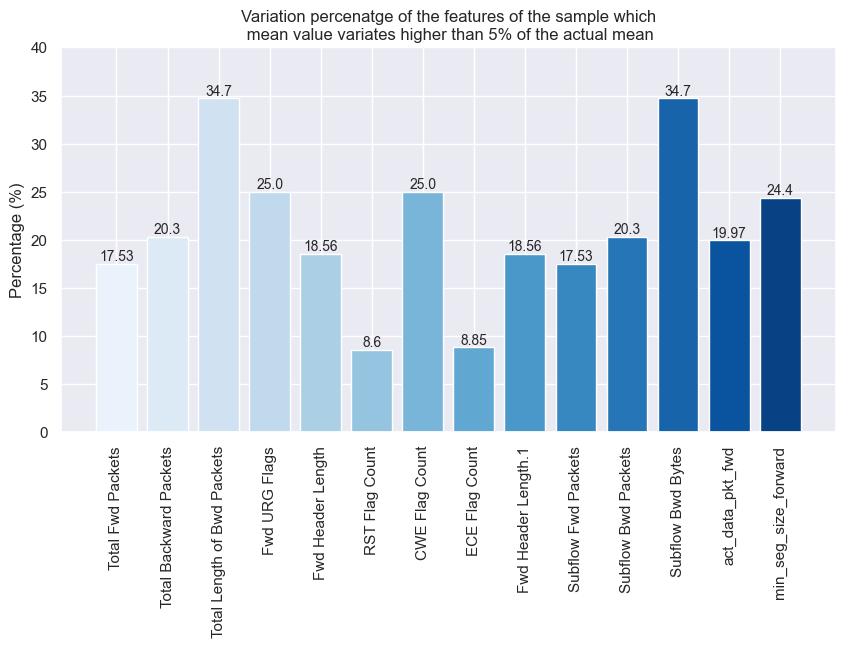

In [30]:
labels = [t[0] for t in high_variations]
values = [t[1] for t in high_variations]

colors = sns.color_palette('Blues', n_colors=len(labels))
fig, ax = plt.subplots(figsize = (10, 5))
ax.bar(labels, values, color = colors)

for i in range(len(labels)):
    ax.text(i, values[i], str(round(values[i], 2)), ha = 'center', va = 'bottom', fontsize = 10)

plt.xticks(rotation = 90)
ax.set_title('Variation percenatge of the features of the sample which\n mean value variates higher than 5% of the actual mean')
ax.set_ylabel('Percentage (%)')
ax.set_yticks(np.arange(0, 41, 5))
plt.show()

In [31]:
# Printing the unique value count
indent = '{:<3} {:<30}: {}'
print('Unique value count for: ')
for i, feature in enumerate(list(sampled_data.columns)[:-1], start = 1):
    print(indent.format(f'{i}.', feature, sampled_data[feature].nunique()))

Unique value count for: 
1.  Destination Port              : 33346
2.  Flow Duration                 : 256627
3.  Total Fwd Packets             : 659
4.  Total Backward Packets        : 820
5.  Total Length of Fwd Packets   : 9070
6.  Total Length of Bwd Packets   : 23963
7.  Fwd Packet Length Max         : 3701
8.  Fwd Packet Length Min         : 236
9.  Fwd Packet Length Mean        : 34946
10. Fwd Packet Length Std         : 66038
11. Bwd Packet Length Max         : 3936
12. Bwd Packet Length Min         : 449
13. Bwd Packet Length Mean        : 45585
14. Bwd Packet Length Std         : 62492
15. Flow Bytes/s                  : 346855
16. Flow Packets/s                : 288293
17. Flow IAT Mean                 : 274182
18. Flow IAT Std                  : 229680
19. Flow IAT Max                  : 167860
20. Flow IAT Min                  : 45941
21. Fwd IAT Total                 : 119784
22. Fwd IAT Mean                  : 164556
23. Fwd IAT Std                   : 148638
24. Fwd IAT

In [32]:
# Correlation matrix for sampled data
corr_matrix = sampled_data.corr(numeric_only = True).round(2)
corr_matrix.style.background_gradient(cmap = 'coolwarm', axis = None).format(precision = 2)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Attack Number
Destination Port,1.00,-0.17,-0.00,-0.00,0.02,-0.00,0.09,-0.05,0.14,0.12,-0.21,-0.26,-0.24,-0.19,0.07,0.36,-0.11,-0.13,-0.13,-0.02,-0.17,-0.11,-0.11,-0.13,-0.05,-0.12,-0.07,-0.04,-0.06,-0.05,0.23,nan,0.01,nan,0.00,0.00,0.35,0.15,-0.26,-0.14,-0.17,-0.14,-0.08,-0.04,0.23,-0.01,-0.22,0.58,0.52,0.01,-0.01,0.03,-0.17,0.14,-0.24,0.00,nan,nan,nan,nan,nan,nan,-0.00,0.02,-0.00,-0.00,-0.13,0.21,-0.00,0.00,-0.04,-0.05,-0.06,-0.03,-0.13,0.01,-0.12,-0.13,-0.12
Flow Duration,-0.17,1.00,0.02,0.02,0.10,0.02,0.27,-0.12,0.14,0.23,0.49,-0.24,0.45,0.43,-0.02,-0.11,0.54,0.74,0.78,0.06,1.00,0.54,0.72,0.78,0.21,0.82,0.41,0.52,0.58,0.21,-0.02,nan,-0.00,nan,-0.00,0.00,-0.10,-0.08,-0.25,0.50,0.42,0.45,0.27,0.22,-0.02,0.01,0.18,0.04,-0.12,-0.00,0.01,-0.17,0.40,0.14,0.45,-0.00,nan,nan,nan,nan,nan,nan,0.02,0.10,0.02,0.02,0.09,-0.03,0.02,-0.00,0.19,0.25,0.29,0.12,0.76,0.24,0.78,0.73,0.21
Total Fwd Packets,-0.00,0.02,1.00,1.00,0.69,0.99,0.01,-0.00,-0.00,0.00,0.03,-0.01,0.02,0.01,0.00,-0.00,-0.00,-0.00,0.00,-0.00,0.02,-0.00,-0.00,0.00,-0.00,0.02,-0.00,-0.00,0.00,-0.00,0.00,nan,-0.00,nan,0.00,0.02,-0.00,-0.00,-0.01,0.03,0.03,0.01,0.01,-0.00,0.00,-0.00,0.01,0.00,-0.00,-0.00,-0.00,0.00,0.02,-0.00,0.02,0.00,nan,nan,nan,nan,nan,nan,1.00,0.69,1.00,0.99,0.00,-0.00,0.87,-0.00,0.12,0.01,0.08,0.13,0.00,0.00,0.00,0.00,-0.00
Total Backward Packets,-0.00,0.02,1.00,1.00,0.68,0.99,0.01,-0.00,-0.00,0.00,0.03,-0.01,0.02,0.01,0.00,-0.00,-0.00,-0.00,0.00,-0.00,0.02,-0.00,-0.00,0.00,-0.00,0.02,-0.00,-0.00,0.00,-0.00,0.00,nan,-0.00,nan,0.00,0.02,-0.00,-0.00,-0.01,0.03,0.03,0.01,0.01,-0.00,0.00,-0.00,0.01,0.00,-0.00,-0.00,-0.00,0.00,0.03,-0.00,0.02,0.00,nan,nan,nan,nan,nan,nan,1.00,0.68,1.00,0.99,0.00,-0.00,0.86,0.00,0.12,0.01,0.08,0.13,0.00,0.00,0.00,0.00,-0.00
Total Length of Fwd Packets,0.02,0.10,0.69,0.68,1.00,0.69,0.31,-0.00,0.29,0.25,0.04,-0.05,0.03,0.01,0.00,-0.02,0.01,0.02,0.04,-0.00,0.10,0.01,0.04,0.04,-0.01,0.12,0.01,0.06,0.07,-0.01,0.01,nan,-0.00,nan,-0.00,0.01,-0.02,-0.02,-0.05,0.12,0.13,0.09,0.06,-0.01,0.01,0.01,0.07,-0.01,-0.01,-0.00,0.01,-0.02,0.12,0.29,0.03,-0.00,nan,nan,nan,nan,nan,nan,0.69,1.00,0.68,0.69,0.05,0.01,0.78,-0.00,0.19,0.12,0.19,0.16,0.03,0.04,0.04,0.03,-0.03
Total Length of Bwd Packets,-0.00,0.02,0.99,0.99,0.69,1.00,0.01,-0.00,-0.00,-0.00,0.03,-0.00,0.02,0.01,0.00,-0.00,-0.00,-0.00,0.00,-0.00,0.02,-0.00,-0.00,-0.00,-0.00,0.02,-0.00,-0.00,0.00,-0.00,0.00,nan,-0.00,nan,0.00,0.02,-0.00,-0.00,-0.01,0.03,0.03,0.01,0.01,-0.00,0.00,-0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00,0.02,-0.00,0.02,0.00,nan,nan,nan,nan,nan,nan,0.99,0.69,0.99,1.00,0.00,-0.00,0.88,0.00,0.11,0.00,0.07,0.13,0.00,-0.00,0.00,0.00,-0.00
Fwd Packet Length Max,0.09,0.27,0.01,0.01,0.31,0.01,1.00,-0.01,0.

In [33]:
sampled_data.drop('Attack Number', axis = 1, inplace = True)
data.drop('Attack Number', axis = 1, inplace = True)

In [34]:
# Identifying outliers
numeric_data = sampled_data.select_dtypes(include = ['float', 'int'])
q1 = numeric_data.quantile(0.25)
q3 = numeric_data.quantile(0.75)
iqr = q3 - q1
outlier = (numeric_data < (q1 - 1.5 * iqr)) | (numeric_data > (q3 + 1.5 * iqr))
outlier_count = outlier.sum()
outlier_percentage = round(outlier.mean() * 100, 2)
outlier_stats = pd.concat([outlier_count, outlier_percentage], axis = 1)
outlier_stats.columns = ['Outlier Count', 'Outlier Percentage']

print(outlier_stats)

                             Outlier Count  Outlier Percentage
Destination Port                    109246               21.66
Flow Duration                        93195               18.47
Total Fwd Packets                    50245                9.96
Total Backward Packets               47509                9.42
Total Length of Fwd Packets          62790               12.45
...                                    ...                 ...
Active Min                          111387               22.08
Idle Mean                           113092               22.42
Idle Std                             45767                9.07
Idle Max                            113092               22.42
Idle Min                            113092               22.42

[78 rows x 2 columns]


In [35]:
# Identifying outliers based on attack type
outlier_counts = {}
for i in numeric_data:
    for attack_type in sampled_data['Attack Type'].unique():
        attack_data = sampled_data[i][sampled_data['Attack Type'] == attack_type]
        q1, q3 = np.percentile(attack_data, [25, 75])
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        num_outliers = ((attack_data < lower_bound) | (attack_data > upper_bound)).sum()
        outlier_percent = num_outliers / len(attack_data) * 100
        outlier_counts[(i, attack_type)] = (num_outliers, outlier_percent)

for i in numeric_data:
  print(f'Feature: {i}')
  for attack_type in sampled_data['Attack Type'].unique():
    num_outliers, outlier_percent = outlier_counts[(i, attack_type)]
    print(f'- {attack_type}: {num_outliers} ({outlier_percent:.2f}%)')
  print()

Feature: Destination Port
- BENIGN: 93525 (22.33%)
- DoS: 0 (0.00%)
- DDoS: 2 (0.01%)
- Port Scan: 2305 (12.51%)
- Brute Force: 0 (0.00%)
- Web Attack: 0 (0.00%)
- Bot: 0 (0.00%)
- Infiltration: 0 (0.00%)
- Heartbleed: 0 (0.00%)

Feature: Flow Duration
- BENIGN: 97175 (23.20%)
- DoS: 8444 (21.87%)
- DDoS: 4397 (16.96%)
- Port Scan: 403 (2.19%)
- Brute Force: 443 (23.86%)
- Web Attack: 67 (15.62%)
- Bot: 0 (0.00%)
- Infiltration: 1 (25.00%)
- Heartbleed: 0 (0.00%)

Feature: Total Fwd Packets
- BENIGN: 77615 (18.53%)
- DoS: 464 (1.20%)
- DDoS: 833 (3.21%)
- Port Scan: 272 (1.48%)
- Brute Force: 0 (0.00%)
- Web Attack: 68 (15.85%)
- Bot: 7 (1.82%)
- Infiltration: 1 (25.00%)
- Heartbleed: 0 (0.00%)

Feature: Total Backward Packets
- BENIGN: 59799 (14.28%)
- DoS: 4479 (11.60%)
- DDoS: 0 (0.00%)
- Port Scan: 97 (0.53%)
- Brute Force: 0 (0.00%)
- Web Attack: 36 (8.39%)
- Bot: 7 (1.82%)
- Infiltration: 1 (25.00%)
- Heartbleed: 0 (0.00%)

Feature: Total Length of Fwd Packets
- BENIGN: 80997 (19

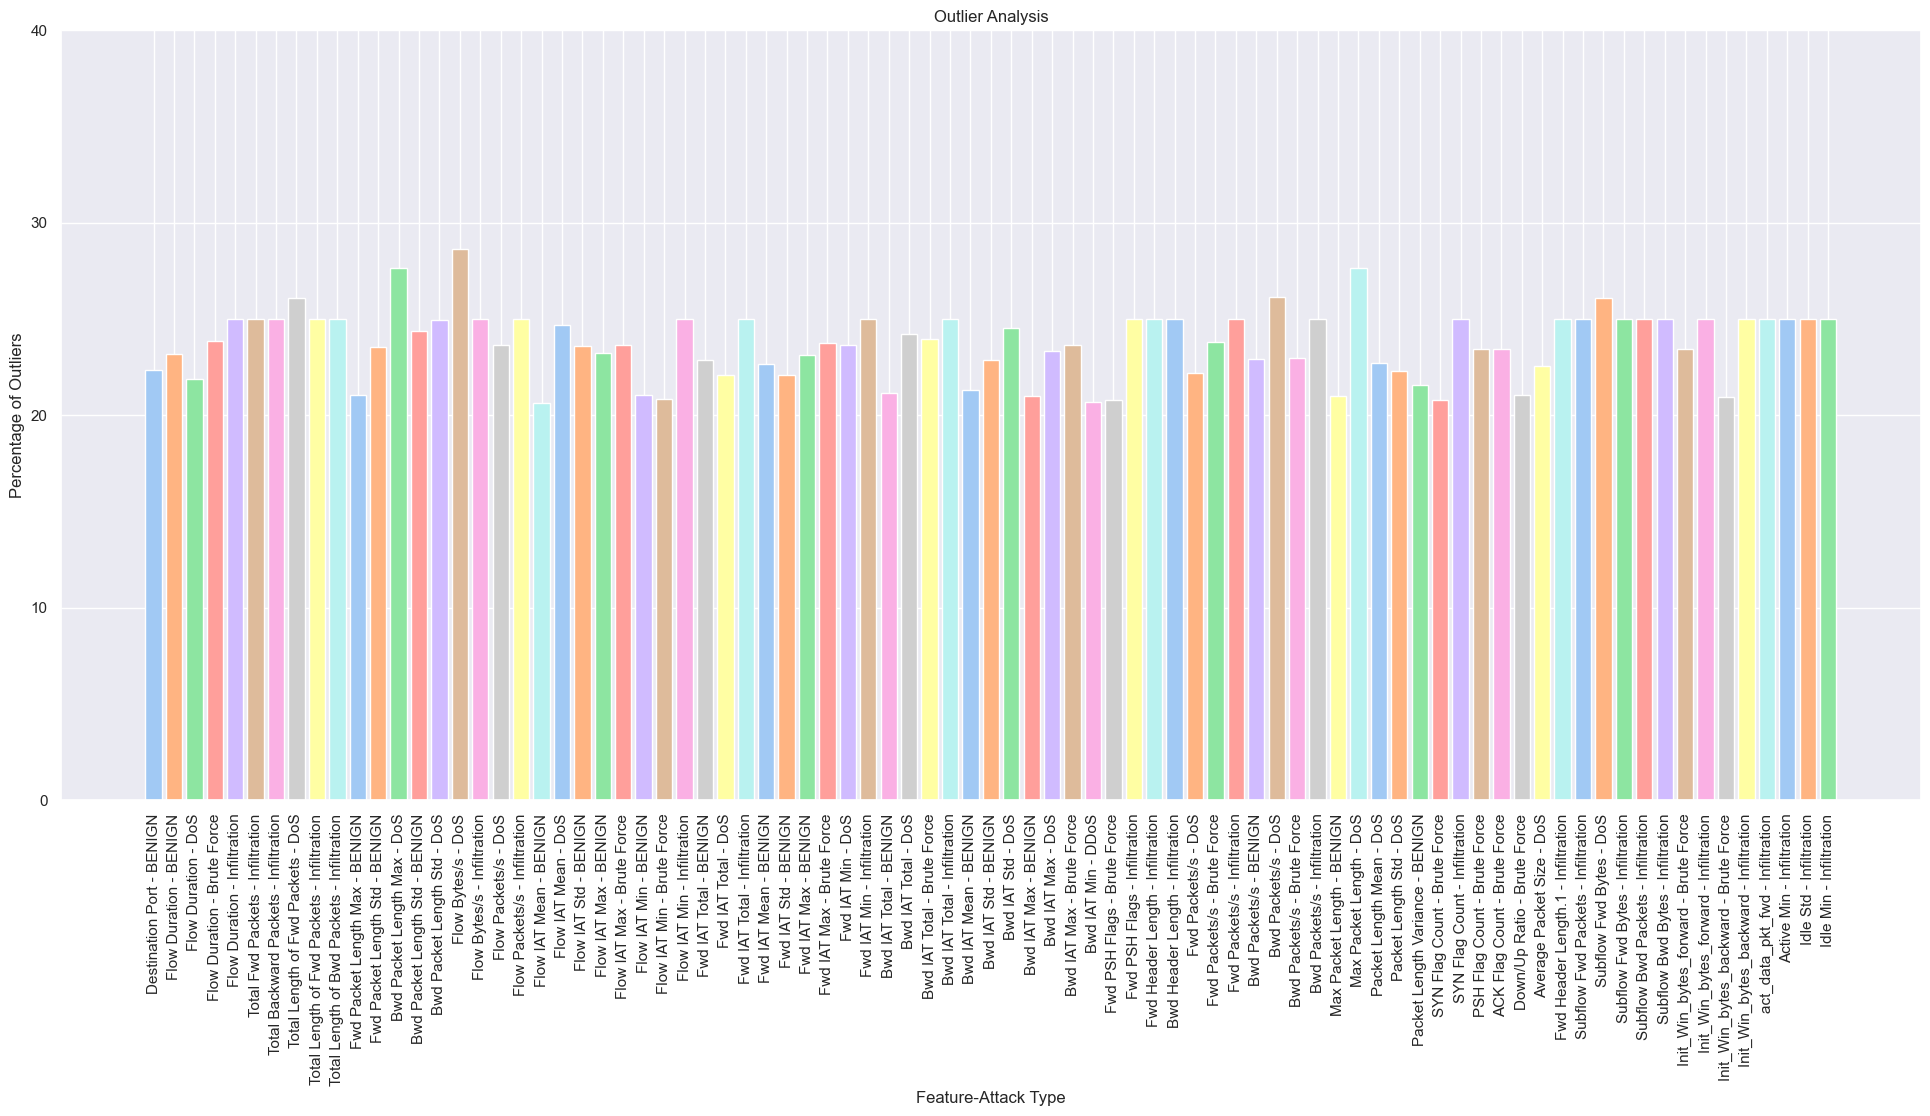

In [36]:
# Plotting the percentage of outliers that are higher than 20%
fig, ax = plt.subplots(figsize = (24, 10))
for i in numeric_data:
    for attack_type in sampled_data['Attack Type'].unique():
        num_outliers, outlier_percent = outlier_counts[(i, attack_type)]
        if outlier_percent > 20:
            ax.bar(f'{i} - {attack_type}', outlier_percent)

ax.set_xlabel('Feature-Attack Type')
ax.set_ylabel('Percentage of Outliers')
ax.set_title('Outlier Analysis')
ax.set_yticks(np.arange(0, 41, 10))
plt.xticks(rotation = 90)
plt.show()

Visualiztion for columns (categorical value)

C:\Users\User\AppData\Local\Temp\ipykernel_16668\323780027.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x = 'Attack Type', data = attacks, palette = 'pastel', order = attacks['Attack Type'].value_counts().index)


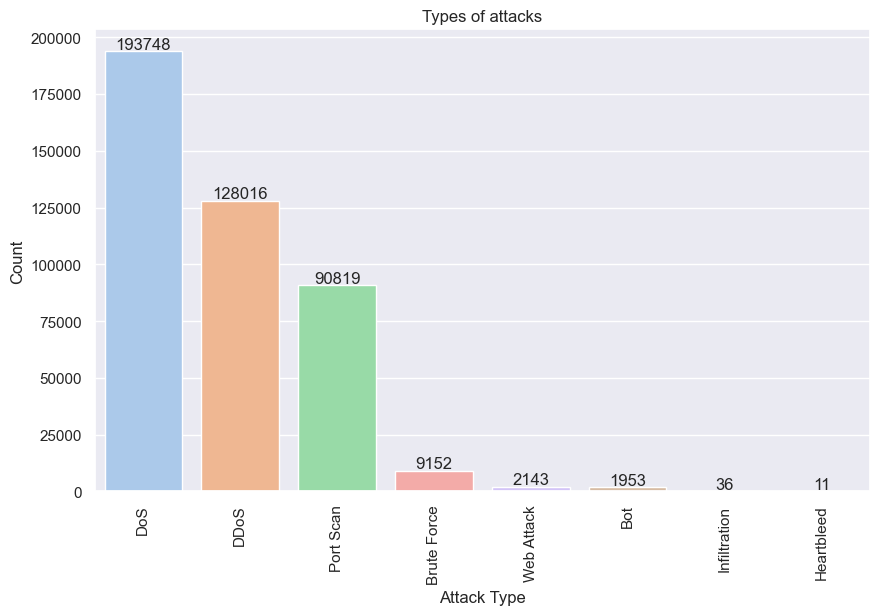

In [37]:
# Different 'Attack Type' in the main dataset excluding 'BENIGN'
attacks = data.loc[data['Attack Type'] != 'BENIGN']

plt.figure(figsize = (10, 6))
ax = sns.countplot(x = 'Attack Type', data = attacks, palette = 'pastel', order = attacks['Attack Type'].value_counts().index)
plt.title('Types of attacks')
plt.xlabel('Attack Type')
plt.ylabel('Count')
plt.xticks(rotation = 90)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.0f}', (p.get_x() + p.get_width() / 2, p.get_height() + 1000), ha = 'center')

plt.show()

In [38]:
data.groupby('Attack Type').first()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
Attack Type,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
BENIGN,49188,4,2,0,12,0,6,6,6.000000,0.000000,0,0,0.000000,0.000000,3.000000e+06,500000.000000,4.000000e+00,0.000000e+00,4,4,4,4.000000e+00,0.000000e+00,4,4,0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,40,0,500000.000000,0.000000,6,6,6.000000,0.000000,0.000000e+00,0,0,0,0,1,1,0,0,0,9.000000,6.000000,0.000000,40,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.00000,0,0,0.0,0.00000,0,0
Bot,8080,60202640,9,9,322,256,322,0,35.777778,107.333333,256,0,28.444444,85.333333,9.600908e+00,0.298990,3.541332e+06,4.901981e+06,10200000,47,51200000,6.396442e+06,5.268490e+06,10200000,234,60200000,7.518954e+06,4.645137e+06,10300000,637,0,0,0,0,296,296,0.149495,0.149495,0,322,30.421053,91.783753,8.424257e+03,0,0,0,1,0,0,0,0,1,32.111111,35.777778,28.444444,296,0,0,0,0,0,0,9,322,9,256,29200,110,1,32,63678.2,22252.53596,103175,50911,10200000.0,34941.27201,10200000,10100000
Brute Force,80,5216127,3,1,0,0,0,0,0.000000,0.000000,0,0,0.000000,0.000000,0.000000e+00,0.766852,1.738709e+06,3.010454e+06,5214882,124,5216127,2.608064e+06,3.686598e+06,5214882,1245,0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,104,40,0.575139,0.191713,0,0,0.000000,0.000000,0.000000e+00,0,0,0,1,0,0,0,0,0,0.000000,0.000000,0.000000,104,0,0,0,0,0,0,3,0,1,0,29200,28960,0,32,0.0,0.00000,0,0,0.0,0.00000,0,0
DDoS,80,1293792,3,7,26,11607,20,0,8.666667,10.263203,5840,0,1658.142857,2137.297080,8.991399e+03,7.729218,1.437547e+05,4.308658e+05,1292730,2,747,3.735000e+02,5.239661e+02,744,3,1293746,2.156243e+05,5.276719e+05,1292730,2,0,0,0,0,72,152,2.318765,5.410452,0,5840,1057.545455,1853.437529,3.435231e+06,0,0,0,1,0,0,0,0,2,1163.300000,8.666667,1658.142857,72,0,0,0,0,0,0,3,26,7,11607,8192,229,2,20,0.0,0.00000,0,0,0.0,0.00000,0,0
DoS,80,5169956,8,6,1101,4222,410,0,137.625000,185.758628,3525,0,703.666667,1395.868284,1.029603e+03,2.707953,3.976889e+05,1.368409e+06,4951173,112,218783,3.125471e+04,3.068629e+04,78311,219,5169833,1.033967e+06,2.218975e+06,5002421,840,0,0,0,0,172,132,1.547402,1.160551,0,3525,354.866667,895.115146,8.012311e+05,0,0,0,1,0,0,0,0,0,380.214286,137.625000,703.666667,172,0,0,0,0,0,0,8,1101,6,4222,8192,254,7,20,0.0,0.00000,0,0,0.0,0.00000,0,0
Heartbleed,444,119302728,2685,1729,8299,7556917,517,0,3.090875,16.858421,17376,0,4370.686524,2566.935004,6.341193e+04,36.998316,2.703438e+04,1.746258e+05,5024984,0,119000000,4.444951e+04,2.224617e+05,5025702,0,119000000,6.904091e+04,2.738674e+05,5024984,1,0,0,0,0,85928,55336,22.505772,14.492544,0,17376,1713.525708,2669.389319,7.125639e+06,0,0,0,1,0,0,0,0,0,1713.913910,3.090875,4370.686524,85928,0,0,0,0,0,0,2685,8299,1729,7556917,29200,235,118,32,2217.0,0.00000,2217,2217,5024984.0,0.00000

DATA PREPROCESING

In [39]:
# For improving performance and reduce memory-related errors
old_memory_usage = data.memory_usage().sum() / 1024 ** 2
print(f'Initial memory usage: {old_memory_usage:.2f} MB')
for col in data.columns:
    col_type = data[col].dtype
    if col_type != object:
        c_min = data[col].min()
        c_max = data[col].max()
        # Downcasting float64 to float32
        if str(col_type).find('float') >= 0 and c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
            data[col] = data[col].astype(np.float32)

        # Downcasting int64 to int32
        elif str(col_type).find('int') >= 0 and c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
            data[col] = data[col].astype(np.int32)

new_memory_usage = data.memory_usage().sum() / 1024 ** 2
print(f"Final memory usage: {new_memory_usage:.2f} MB")

Initial memory usage: 1520.28 MB
Final memory usage: 789.01 MB


In [40]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2522362 entries, 0 to 2522361
Data columns (total 79 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   Destination Port             int32  
 1   Flow Duration                int32  
 2   Total Fwd Packets            int32  
 3   Total Backward Packets       int32  
 4   Total Length of Fwd Packets  int32  
 5   Total Length of Bwd Packets  int32  
 6   Fwd Packet Length Max        int32  
 7   Fwd Packet Length Min        int32  
 8   Fwd Packet Length Mean       float32
 9   Fwd Packet Length Std        float32
 10  Bwd Packet Length Max        int32  
 11  Bwd Packet Length Min        int32  
 12  Bwd Packet Length Mean       float32
 13  Bwd Packet Length Std        float32
 14  Flow Bytes/s                 float32
 15  Flow Packets/s               float32
 16  Flow IAT Mean                float32
 17  Flow IAT Std                 float32
 18  Flow IAT Max                 int32  
 19  

In [41]:
data.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Destination Port,2522362.0,8.704762e+03,1.902507e+04,0.0,53.0,80.0,443.00,65535.0
Flow Duration,2522362.0,1.658132e+07,3.522426e+07,-13.0,208.0,50577.0,5329717.25,119999998.0
Total Fwd Packets,2522362.0,1.027627e+01,7.941738e+02,1.0,2.0,2.0,6.00,219759.0
Total Backward Packets,2522362.0,1.156596e+01,1.056594e+03,0.0,1.0,2.0,5.00,291922.0
Total Length of Fwd Packets,2522362.0,6.115751e+02,1.058499e+04,0.0,12.0,66.0,332.00,12900000.0
...,...,...,...,...,...,...,...,...
Active Min,2522362.0,6.542300e+04,6.109712e+05,0.0,0.0,0.0,0.00,110000000.0
Idle Mean,2522362.0,9.331577e+06,2.484157e+07,0.0,0.0,0.0,0.00,120000000.0
Idle Std,2522362.0,5.654432e+05,4.872678e+06,0.0,0.0,0.0,0.00,76900000.0
Idle Max,2522362.0,9.757716e+06,2.561067e+07,0.0,0.0,0.0,0.00,120000000.0


In [42]:
# Dropping columns with only one unique value
num_unique = data.nunique()
one_variable = num_unique[num_unique == 1]
not_one_variable = num_unique[num_unique > 1].index

dropped_cols = one_variable.index
data = data[not_one_variable]

print('Dropped columns:')
dropped_cols

Dropped columns:


Index(['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk',
       'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk',
       'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate'],
      dtype='object')

In [43]:
# Columns after removing non variant columns
data.columns

Index(['Destination Port', 'Flow Duration', 'Total Fwd Packets',
       'Total Backward Packets', 'Total Length of Fwd Packets',
       'Total Length of Bwd Packets', 'Fwd Packet Length Max',
       'Fwd Packet Length Min', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Min', 'Bwd Packet Length Mean',
       'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s',
       'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
       'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
       'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std',
       'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd URG Flags',
       'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s',
       'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length',
       'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance',
       'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count',

Apllying PCA before it StandardScaler

In [44]:
# Standardizing the dataset
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

features = data.drop('Attack Type', axis = 1)
attacks = data['Attack Type']

# Handle missing values by imputing with mean
imputer = SimpleImputer(strategy='mean')
features_imputed = imputer.fit_transform(features)

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features_imputed)

In [45]:
from sklearn.decomposition import IncrementalPCA

size = len(features.columns) // 2
ipca = IncrementalPCA(n_components = size, batch_size = 500)
for batch in np.array_split(scaled_features, len(features) // 500):
    ipca.partial_fit(batch)

print(f'information retained: {sum(ipca.explained_variance_ratio_):.2%}')

information retained: 99.30%


In [46]:
transformed_features = ipca.transform(scaled_features)
new_data = pd.DataFrame(transformed_features, columns = [f'PC{i+1}' for i in range(size)])
new_data['Attack Type'] = attacks.values

In [47]:
new_data

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,PC29,PC30,PC31,PC32,PC33,PC34,PC35,Attack Type
0,-2.357657,-0.054983,0.577406,0.734623,3.730319,0.234489,-0.015694,-0.215638,-0.278587,1.087704,0.032929,0.067845,1.637886,0.371247,-0.794858,0.003746,0.069433,0.615087,-0.657960,-0.596586,-0.350853,-0.714207,-1.721544,-0.069708,-0.420200,0.904774,-0.148007,-0.334134,1.488020,-0.163725,-0.219340,-0.004577,0.002609,0.034142,-0.015858,BENIGN
1,-2.884084,-0.069950,0.911469,1.763597,8.846468,0.620256,-0.056832,1.105791,1.905561,-2.755125,-0.950260,-0.843530,6.051285,1.568221,-4.732682,-0.120468,1.314000,1.950606,-0.497011,-0.591721,-0.200018,-0.566858,-5.606629,0.295878,1.603668,0.594205,0.282537,-2.347170,2.239606,-0.641139,-0.367554,0.010519,0.000644,0.125862,-0.190793,BENIGN
2,-2.416999,-0.056687,0.615387,0.851070,4.304205,0.275615,-0.020435,-0.070657,-0.035477,0.664696,-0.075941,-0.032892,2.131674,0.504159,-1.230586,-0.009896,0.206620,0.764258,-0.642379,-0.598001,-0.334988,-0.697196,-2.155968,-0.032300,-0.196711,0.868320,-0.101759,-0.545334,1.572334,-0.214028,-0.234649,-0.003047,0.002401,0.044013,-0.035279,BENIGN
3,-2.884934,-0.069990,0.912332,1.765714,8.851892,0.618519,-0.057002,1.103946,1.905988,-2.751152,-0.949887,-0.843003,6.054696,1.568136,-4.730875,-0.120308,1.312902,1.951386,-0.499312,-0.593677,-0.200912,-0.566219,-5.609377,0.292665,1.602282,0.592258,0.280946,-2.334699,2.240410,-0.638396,-0.366395,0.010371,0.000654,0.125542,-0.190778,BENIGN
4,-1.505237,0.080886,-0.504405,0.290378,-0.539306,0.746122,0.100443,0.732593,-1.145795,-0.563035,-0.043682,-0.207978,-0.433672,0.033303,-0.609108,0.018240,-0.249045,-0.475471,-0.140386,0.113642,-0.114060,0.096081,0.291839,0.385989,-0.255700,-0.689648,-0.599151,0.116516,0.794995,-0.211031,0.042491,-0.014254,0.000957,-0.052009,0.001371,BENIGN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2522357,-2.270962,-0.048462,0.480017,0.461241,2.163754,-0.144751,-0.016023,-0.777648,-0.907837,2.711272,0.414036,0.406243,0.989950,-0.084144,0.911251,0.011133,-0.030319,0.339069,-0.328384,-0.307931,-0.436381,-1.016987,-0.319067,-0.280828,-0.369527,0.762727,-0.043134,0.788073,0.785498,0.247968,0.036181,-0.017415,0.001899,0.005528,-0.005963,BENIGN
2522358,-2.267916,-0.048377,0.478588,0.458004,2.143937,-0.146770,-0.015955,-0.780455,-0.910974,2.717914,0.416606,0.409094,0.957161,-0.091130,0.929028,0.012650,-0.044750,0.326783,-0.347775,-0.340561,-0.425546,-1.035396,-0.346273,-0.275017,-0.359998,0.758206,-0.041195,0.789449,0.786852,0.249315,0.038015,-0.017560,0.001901,0.005081,-0.006289,BENIGN
2522359,-2.267231,-0.048358,0.478266,0.457253,2.139475,-0.147210,-0.015939,-0.781072,-0.911659,2.719342,0.417170,0.409722,0.949851,-0.092675,0.932950,0.012985,-0.047943,0.324054,-0.352064,-0.347781,-0.423139,-1.039483,-0.352267,-0.273714,-0.357876,0.757180,-0.040761,0.789594,0.787158,0.249568,0.038401,-0.017590,0.001901,0.004984,-0.006360,BENIGN
2522360,-2.102457,-0.041899,0.361546,0.268811,1.795711,0.284643,0.006676,-0.296127,-0.630981,0.966783,0.082099,0.111277,-0.169056,0.134347,-0.233606,0.075695,-0.641959,-0.128275,-0.838003,-0.492697,-0.516236,-0.084828,-0.588266,0.123005,-0.998477,0.312901,-0.372806,1.793372,-0.925542,0.297553,0.128612,-0.006209,0.002178,-0.077706,0.032578,BENIGN


Applying KNN MOdel 

In [48]:
# For cross validation
from sklearn.model_selection import cross_val_score

In [49]:
new_data['Attack Type'].value_counts()

Attack Type
BENIGN          2096484
DoS              193748
DDoS             128016
Port Scan         90819
Brute Force        9152
Web Attack         2143
Bot                1953
Infiltration         36
Heartbleed           11
Name: count, dtype: int64

In [50]:
class_counts = new_data['Attack Type'].value_counts()
selected_classes = class_counts[class_counts > 1950]
class_names = selected_classes.index
selected = new_data[new_data['Attack Type'].isin(class_names)]

dfs = []
for name in class_names:
  df = selected[selected['Attack Type'] == name]
  if len(df) > 2500:
    df = df.sample(n = 5000, random_state = 0)

  dfs.append(df)

df = pd.concat(dfs, ignore_index = True)
df['Attack Type'].value_counts()

MemoryError: Unable to allocate 674. MiB for an array with shape (2522315, 35) and data type float64

In [ ]:
from imblearn.over_sampling import SMOTE

X = df.drop('Attack Type', axis=1)
y = df['Attack Type']

smote = SMOTE(sampling_strategy='auto', random_state=0)
X_upsampled, y_upsampled = smote.fit_resample(X, y)

blnc_data = pd.DataFrame(X_upsampled)
blnc_data['Attack Type'] = y_upsampled
blnc_data = blnc_data.sample(frac=1)

blnc_data['Attack Type'].value_counts()

Attack Type
BENIGN         5000
DDoS           5000
Brute Force    5000
Web Attack     5000
DoS            5000
Port Scan      5000
Bot            5000
Name: count, dtype: int64

In [ ]:
from sklearn.model_selection import train_test_split
features = blnc_data.drop('Attack Type', axis = 1)
labels = blnc_data['Attack Type']


X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size = 0.25, random_state = 0)

KNN MODEL

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn1 = KNeighborsClassifier(n_neighbors = 16)
knn1.fit(X_train, y_train)

cv_knn1 = cross_val_score(knn1, X_train, y_train, cv = 5)
print('K Nearest Neighbors Model 1')
print(f'\nCross-validation scores:', ', '.join(map(str, cv_knn1)))
print(f'\nMean cross-validation score: {cv_knn1.mean():.2f}')

K Nearest Neighbors Model 1

Cross-validation scores: 0.9761904761904762, 0.968, 0.9744761904761905, 0.9721904761904762, 0.9708571428571429

Mean cross-validation score: 0.97


In [ ]:
knn2 = KNeighborsClassifier(n_neighbors = 8)
knn2.fit(X_train, y_train)

cv_knn2 = cross_val_score(knn2, X_train, y_train, cv = 5)
print('K Nearest Neighbors Model 1')
print(f'\nCross-validation scores:', ', '.join(map(str, cv_knn2)))
print(f'\nMean cross-validation score: {cv_knn2.mean():.2f}')

K Nearest Neighbors Model 1

Cross-validation scores: 0.9824761904761905, 0.9756190476190476, 0.9815238095238096, 0.9801904761904762, 0.9752380952380952

Mean cross-validation score: 0.98


Performance Metric

In [ ]:
# Importing necessary functions
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report, \
 roc_auc_score, roc_curve, auc, precision_recall_curve

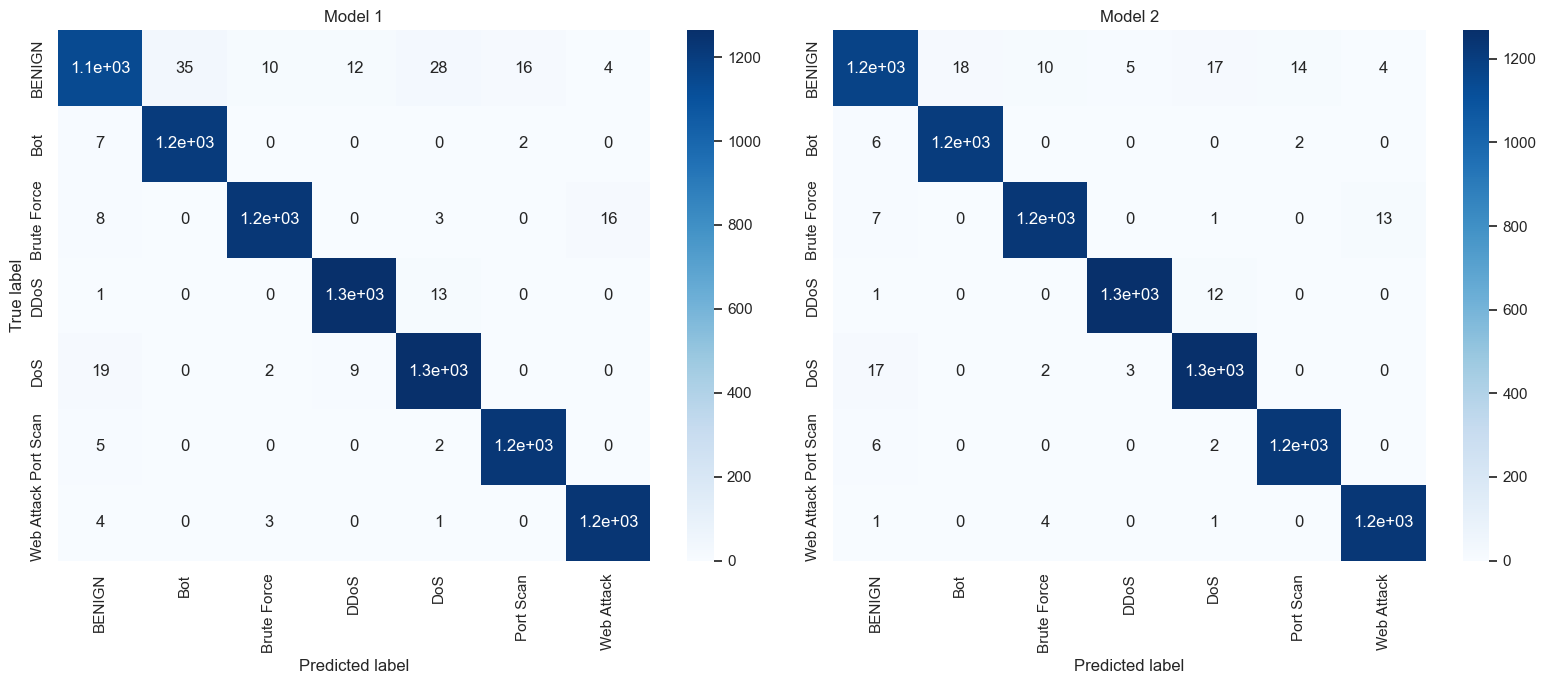

In [ ]:
y_pred_knn1 = knn1.predict(X_test)
y_pred_knn2 = knn2.predict(X_test)

conf_matrix_model1 = confusion_matrix(y_test, y_pred_knn1)
conf_matrix_model2 = confusion_matrix(y_test, y_pred_knn2)

fig, axs = plt.subplots(1, 2, figsize = (16, 7))

sns.heatmap(conf_matrix_model1, annot = True, cmap = 'Blues', ax = axs[0], xticklabels = knn1.classes_, yticklabels = knn1.classes_)
axs[0].set_title('Model 1')

sns.heatmap(conf_matrix_model2, annot = True, cmap = 'Blues', ax = axs[1], xticklabels = knn2.classes_, yticklabels = knn2.classes_)
axs[1].set_title('Model 2')

axs[0].set_xlabel('Predicted label')
axs[0].set_ylabel('True label')
axs[1].set_xlabel('Predicted label')

fig.tight_layout()
plt.show()

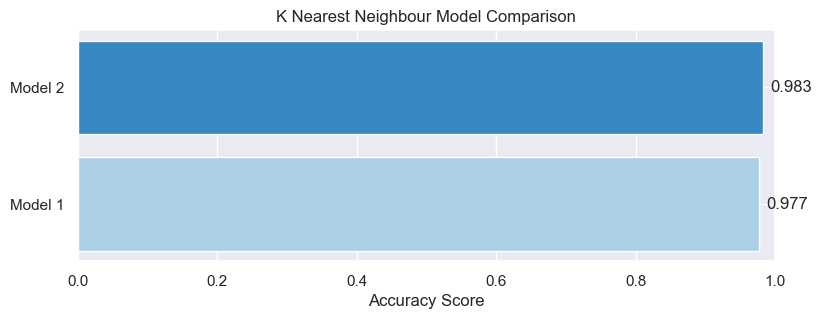

In [ ]:
palette = sns.color_palette('Blues', n_colors = 2)

acc1 = accuracy_score(y_pred_knn1, y_test)
acc2 = accuracy_score(y_pred_knn2, y_test)

labels = ['Model 1', 'Model 2']
scores = [acc1, acc2]

fig, ax = plt.subplots(figsize = (9, 3))
ax.barh(labels, scores, color = palette)
ax.set_xlim([0, 1])
ax.set_xlabel('Accuracy Score')
ax.set_title('K Nearest Neighbour Model Comparison')

for i, v in enumerate(scores):
    ax.text(v + 0.01, i, str(round(v, 3)), ha = 'left', va = 'center')

plt.show()

Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# Define the parameter space for KNN
param_dist = {
    'n_neighbors': randint(1, 31),  # Randomly sample n_neighbors from 1 to 30
    'weights': ['uniform', 'distance'],  # Weight function
    'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],  # Algorithm for computing neighbors
    'p': [1, 2]  # Power parameter for Minkowski distance (1=Manhattan, 2=Euclidean)
}

# Create a KNN classifier
knn = KNeighborsClassifier()

# Set up RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=knn,
    param_distributions=param_dist,
    n_iter=50,  # Number of parameter settings sampled
    cv=5,  # 5-fold cross-validation
    scoring='accuracy',  # Evaluation metric
    random_state=42,  # For reproducibility
    n_jobs=-1,  # Use all available cores
    verbose=2  # Print progress
)

# Fit the random search to the data
print("Starting Random Search for KNN Hyperparameter Tuning...")
random_search.fit(X_train, y_train)

# Print the best parameters and best score
print(f"\nBest Parameters: {random_search.best_params_}")
print(f"Best Cross-Validation Score: {random_search.best_score_:.4f}")

# Evaluate on test set
best_knn = random_search.best_estimator_
y_pred_best = best_knn.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred_best)
print(f"Test Set Accuracy with Best Parameters: {test_accuracy:.4f}")

# Compare with original models
print("\nComparison:")
print(f"Original KNN1 (n_neighbors=16): {acc1:.4f}")
print(f"Original KNN2 (n_neighbors=8): {acc2:.4f}")
print(f"Tuned KNN: {test_accuracy:.4f}")

Starting Random Search for KNN Hyperparameter Tuning...
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best Parameters: {'algorithm': 'kd_tree', 'n_neighbors': 1, 'p': 1, 'weights': 'uniform'}
Best Cross-Validation Score: 0.9863
Test Set Accuracy with Best Parameters: 0.9890

Comparison:
Original KNN1 (n_neighbors=16): 0.9771
Original KNN2 (n_neighbors=8): 0.9833
Tuned KNN: 0.9890


Top 10 parameter combinations from random search:
Rank 45: Score=0.9863 (±0.0017), Params={'algorithm': 'kd_tree', 'n_neighbors': 1, 'p': 1, 'weights': 'uniform'}
Rank 17: Score=0.9858 (±0.0018), Params={'algorithm': 'ball_tree', 'n_neighbors': 4, 'p': 1, 'weights': 'distance'}
Rank 15: Score=0.9847 (±0.0024), Params={'algorithm': 'auto', 'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}
Rank 38: Score=0.9847 (±0.0024), Params={'algorithm': 'brute', 'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}
Rank 24: Score=0.9842 (±0.0017), Params={'algorithm': 'ball_tree', 'n_neighbors': 6, 'p': 2, 'weights': 'distance'}
Rank 35: Score=0.9839 (±0.0017), Params={'algorithm': 'auto', 'n_neighbors': 7, 'p': 1, 'weights': 'distance'}
Rank 30: Score=0.9835 (±0.0016), Params={'algorithm': 'ball_tree', 'n_neighbors': 8, 'p': 1, 'weights': 'distance'}
Rank 23: Score=0.9831 (±0.0020), Params={'algorithm': 'ball_tree', 'n_neighbors': 8, 'p': 2, 'weights': 'distance'}
Rank 41: Score=0.9831 (±0.0020), Params={

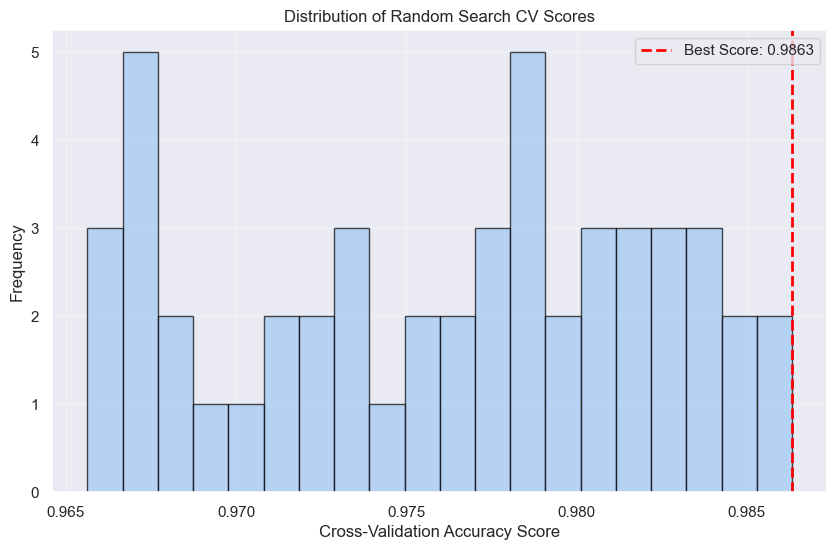


Classification Report for Best KNN Model:
              precision    recall  f1-score   support

      BENIGN       0.98      0.97      0.97      1242
         Bot       0.99      1.00      0.99      1215
 Brute Force       0.99      0.99      0.99      1253
        DDoS       1.00      0.99      1.00      1278
         DoS       0.99      0.99      0.99      1290
   Port Scan       0.99      0.99      0.99      1233
  Web Attack       0.99      0.99      0.99      1239

    accuracy                           0.99      8750
   macro avg       0.99      0.99      0.99      8750
weighted avg       0.99      0.99      0.99      8750



In [ ]:
# Display detailed results of the random search
import pandas as pd

results_df = pd.DataFrame(random_search.cv_results_)
print("Top 10 parameter combinations from random search:")
top_results = results_df.nlargest(10, 'mean_test_score')[['mean_test_score', 'std_test_score', 'params']]
for i, row in top_results.iterrows():
    print(f"Rank {i+1}: Score={row['mean_test_score']:.4f} (±{row['std_test_score']:.4f}), Params={row['params']}")

# Plot the distribution of scores
plt.figure(figsize=(10, 6))
plt.hist(results_df['mean_test_score'], bins=20, edgecolor='black', alpha=0.7)
plt.axvline(random_search.best_score_, color='red', linestyle='--', linewidth=2, label=f'Best Score: {random_search.best_score_:.4f}')
plt.xlabel('Cross-Validation Accuracy Score')
plt.ylabel('Frequency')
plt.title('Distribution of Random Search CV Scores')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Print classification report for the best model
print("\nClassification Report for Best KNN Model:")
print(classification_report(y_test, y_pred_best))

In [ ]:
# Bayesian Search Hyperparameter Tuning using scikit-optimize
from skopt import BayesSearchCV
from skopt.space import Integer, Categorical

# Define the search space for Bayesian optimization
search_spaces = {
    'n_neighbors': Integer(1, 30),  # Integer range for n_neighbors
    'weights': Categorical(['uniform', 'distance']),  # Categorical for weights
    'algorithm': Categorical(['auto', 'ball_tree', 'kd_tree', 'brute']),  # Categorical for algorithm
    'p': Integer(1, 2)  # Integer range for p (1=Manhattan, 2=Euclidean)
}

# Create a KNN classifier
knn_bayes = KNeighborsClassifier()

# Set up BayesSearchCV
bayes_search = BayesSearchCV(
    estimator=knn_bayes,
    search_spaces=search_spaces,
    n_iter=50,  # Number of iterations
    cv=5,  # 5-fold cross-validation
    scoring='accuracy',  # Evaluation metric
    random_state=42,  # For reproducibility
    n_jobs=-1,  # Use all available cores
    verbose=2  # Print progress
)

# Fit the Bayesian search to the data
print("Starting Bayesian Search for KNN Hyperparameter Tuning...")
bayes_search.fit(X_train, y_train)

# Print the best parameters and best score
print(f"\nBest Parameters: {bayes_search.best_params_}")
print(f"Best Cross-Validation Score: {bayes_search.best_score_:.4f}")

# Evaluate on test set
best_knn_bayes = bayes_search.best_estimator_
y_pred_bayes = best_knn_bayes.predict(X_test)
test_accuracy_bayes = accuracy_score(y_test, y_pred_bayes)
print(f"Test Set Accuracy with Best Parameters: {test_accuracy_bayes:.4f}")

# Compare with previous results
print("\nComparison of Hyperparameter Tuning Methods:")
print(f"Original KNN1 (n_neighbors=16): {acc1:.4f}")
print(f"Original KNN2 (n_neighbors=8): {acc2:.4f}")
print(f"Random Search Tuned KNN: {test_accuracy:.4f}")
print(f"Bayesian Search Tuned KNN: {test_accuracy_bayes:.4f}")

Starting Bayesian Search for KNN Hyperparameter Tuning...
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fit